# 1. Exploratory analysis and aging curves

What does a skill-position career look like, and how fast does production decay by position?

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from datascience.features import *
from datascience.model import *
from datascience.collect import load_snapshots, load_trades
table = season_features()
print(table.shape, 'seasons', table.season.min(), '-', table.season.max())
table[['name','position','season','age','games','ppg','next_points']].tail()

(8055, 38) seasons 2012 - 2025


,name,position,season,age,games,ppg,next_points
8050,Terrance Ferguson,TE,2025,22.488706,11,4.736364,NaN
8051,Elijah Arroyo,TE,2025,22.409309,13,2.838462,NaN
8052,Tyler Shough,QB,2025,25.927447,11,14.360000,NaN
8053,Isaiah Bond,WR,2025,21.464750,15,3.646667,NaN
8054,Quinshon Judkins,RB,2025,21.842574,14,12.128571,NaN


## Production by position and age
Median points per game by age shows the shape of a typical career.

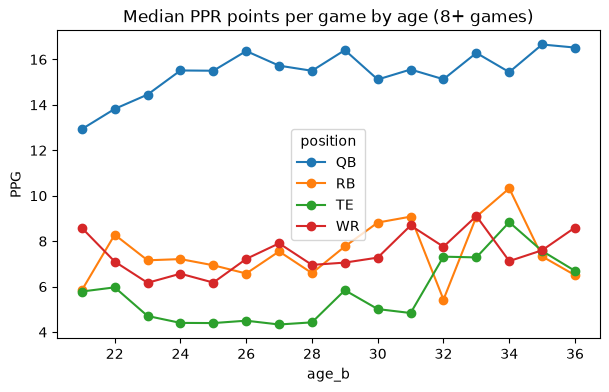

In [2]:
sub = table[(table.games >= 8) & table.age.notna()].copy()
sub['age_b'] = sub.age.round().clip(21, 36)
pivot = sub.pivot_table(index='age_b', columns='position', values='ppg', aggfunc='median')
pivot.plot(figsize=(7, 4), marker='o', title='Median PPR points per game by age (8+ games)')
plt.ylabel('PPG'); plt.show()

## Empirical aging curves
Retention is the ratio of next-season to current-season PPG, pooled over players with 8+ games in both seasons. The running back cliff after 26 is visible; QBs hold value longest.

In [3]:
curves = aging_curves(table)
pd.DataFrame(curves).loc[21:36].round(3)

,QB,RB,WR,TE
21,1.200,1.137,1.157,1.112
22,1.110,1.096,1.114,1.118
23,1.036,1.033,1.068,1.138
24,1.000,0.985,1.026,1.099
25,0.992,0.971,0.999,1.017
26,0.979,0.957,0.970,0.958
27,0.983,0.907,0.936,0.942
28,1.006,0.890,0.909,0.929
29,1.025,0.903,0.893,0.901
30,1.031,0.827,0.866,0.897


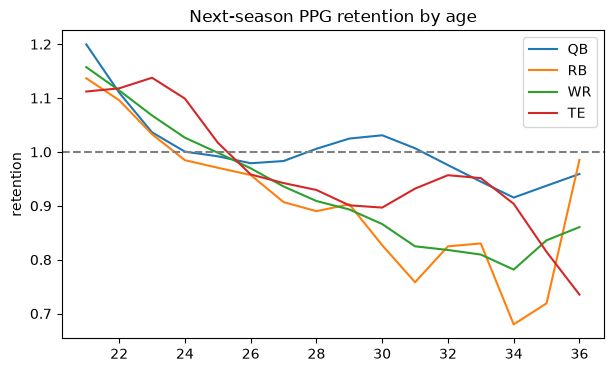

In [4]:
pd.DataFrame(curves).loc[21:36].plot(figsize=(7, 4), title='Next-season PPG retention by age')
plt.axhline(1.0, color='grey', ls='--'); plt.ylabel('retention'); plt.show()

## TE premium
A per-reception bonus helps tight ends because they score a large share of their points on receptions.

In [5]:
print('receptions per PPR point, top-12 TEs over last 5 seasons:', round(te_premium_lift(table), 3))
print('=> a +0.5 bonus lifts a starting TE by about', f'{0.5*te_premium_lift(table):.0%}')

receptions per PPR point, top-12 TEs over last 5 seasons: 0.383
=> a +0.5 bonus lifts a starting TE by about 19%
